
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

# Project root: autonomous-driving-perception
project_dir = Path.cwd().parent

# Use the existing KITTI validation images
val_dir = (
    project_dir / "data" / "kitti_yolo"
    / "images" / "val"
)

images = sorted(val_dir.glob("*.jpg"))

if not images:
    raise FileNotFoundError(
        f"No validation images found in {val_dir}"
    )

image_path = images[0]
image = cv2.imread(str(image_path))

if image is None:
    raise ValueError(f"Could not read image: {image_path}")

print("Image:", image_path.name)
print("Image dimensions:", image.shape[1], "x", image.shape[0])

plt.figure(figsize=(14, 5))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("KITTI Road Scene")
plt.axis("off")
plt.show()


Loaded image: 000138.jpg
Image size: 1242 x 375


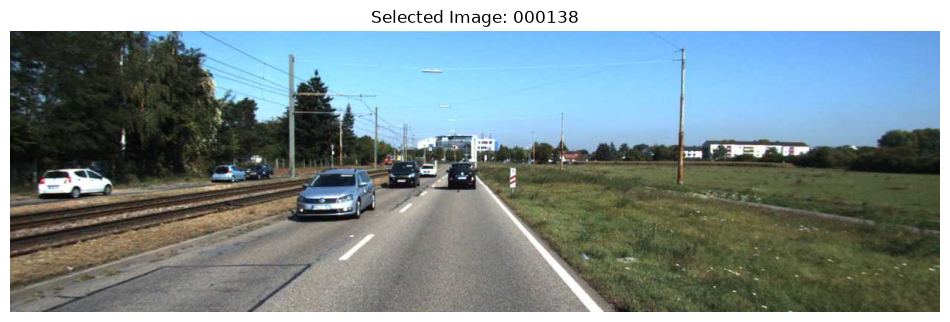

In [26]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

# Enter only the image number
image_number = "000138"

# Load the image from your training folder
image_path = project_dir / "data" / "kitti_yolo" / "images" / "train" / f"{image_number}.jpg"

image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

height, width = image.shape[:2]

print(f"Loaded image: {image_number}.jpg")
print(f"Image size: {width} x {height}")

plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title(f"Selected Image: {image_number}")
plt.axis("off")
plt.show()

In [30]:

# 1. Preprocess
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
edges = cv2.Canny(blurred, 40, 120)

# 2. Mask the lower road region
mask = np.zeros_like(edges)
roi = np.array([[
    (0, height - 1),
    (int(width * 0.35), int(height * 0.52)),
    (int(width * 0.65), int(height * 0.52)),
    (width - 1, height - 1)
]], dtype=np.int32)

cv2.fillPoly(mask, roi, 255)
masked_edges = cv2.bitwise_and(edges, mask)

# 3. Find line segments
lines = cv2.HoughLinesP(
    masked_edges,
    rho=1,
    theta=np.pi / 180,
    threshold=25,
    minLineLength=25,
    maxLineGap=80
)

left_points = []
right_points = []

if lines is not None:
    for x1, y1, x2, y2 in np.asarray(lines).reshape(-1, 4):
        dx, dy = x2 - x1, y2 - y1
        length = np.hypot(dx, dy)

        if length < 25 or abs(dx) < 1:
            continue

        slope = dy / dx
        midpoint_x = (x1 + x2) / 2
        midpoint_y = (y1 + y2) / 2

        if midpoint_y < height * 0.50:
            continue

        if slope < -0.20 and midpoint_x < width * 0.65:
            left_points.extend([(x1, y1), (x2, y2)])
        elif slope > 0.20 and midpoint_x > width * 0.35:
            right_points.extend([(x1, y1), (x2, y2)])

# 4. Fit representative lines
output = image.copy()

def draw_lane_candidate(points, color, side):
    if len(points) < 4:
        return False

    pts = np.asarray(points, dtype=np.float32)
    vx, vy, x0, y0 = cv2.fitLine(
        pts, cv2.DIST_L2, 0, 0.01, 0.01
    ).flatten()

    if abs(vy) < 1e-6:
        return False

    y_bottom = height - 1
    y_top = int(height * 0.55)

    x_bottom = int(x0 + (y_bottom - y0) * vx / vy)
    x_top = int(x0 + (y_top - y0) * vx / vy)

    if not (0 <= x_bottom < width and 0 <= x_top < width):
        return False

    if side == "left" and x_bottom >= width * 0.70:
        return False
    if side == "right" and x_bottom <= width * 0.30:
        return False

    cv2.line(output, (x_bottom, y_bottom), (x_top, y_top), color, 4)
    return True

left_ok = draw_lane_candidate(left_points, (0, 255, 0), "left")
right_ok = draw_lane_candidate(right_points, (0, 165, 255), "right")

print("Left lane candidate:", left_ok)
print("Right lane candidate:", right_ok)
print("Left points:", len(left_points))
print("Right points:", len(right_points))


Left lane candidate: True
Right lane candidate: True
Left points: 60
Right points: 68


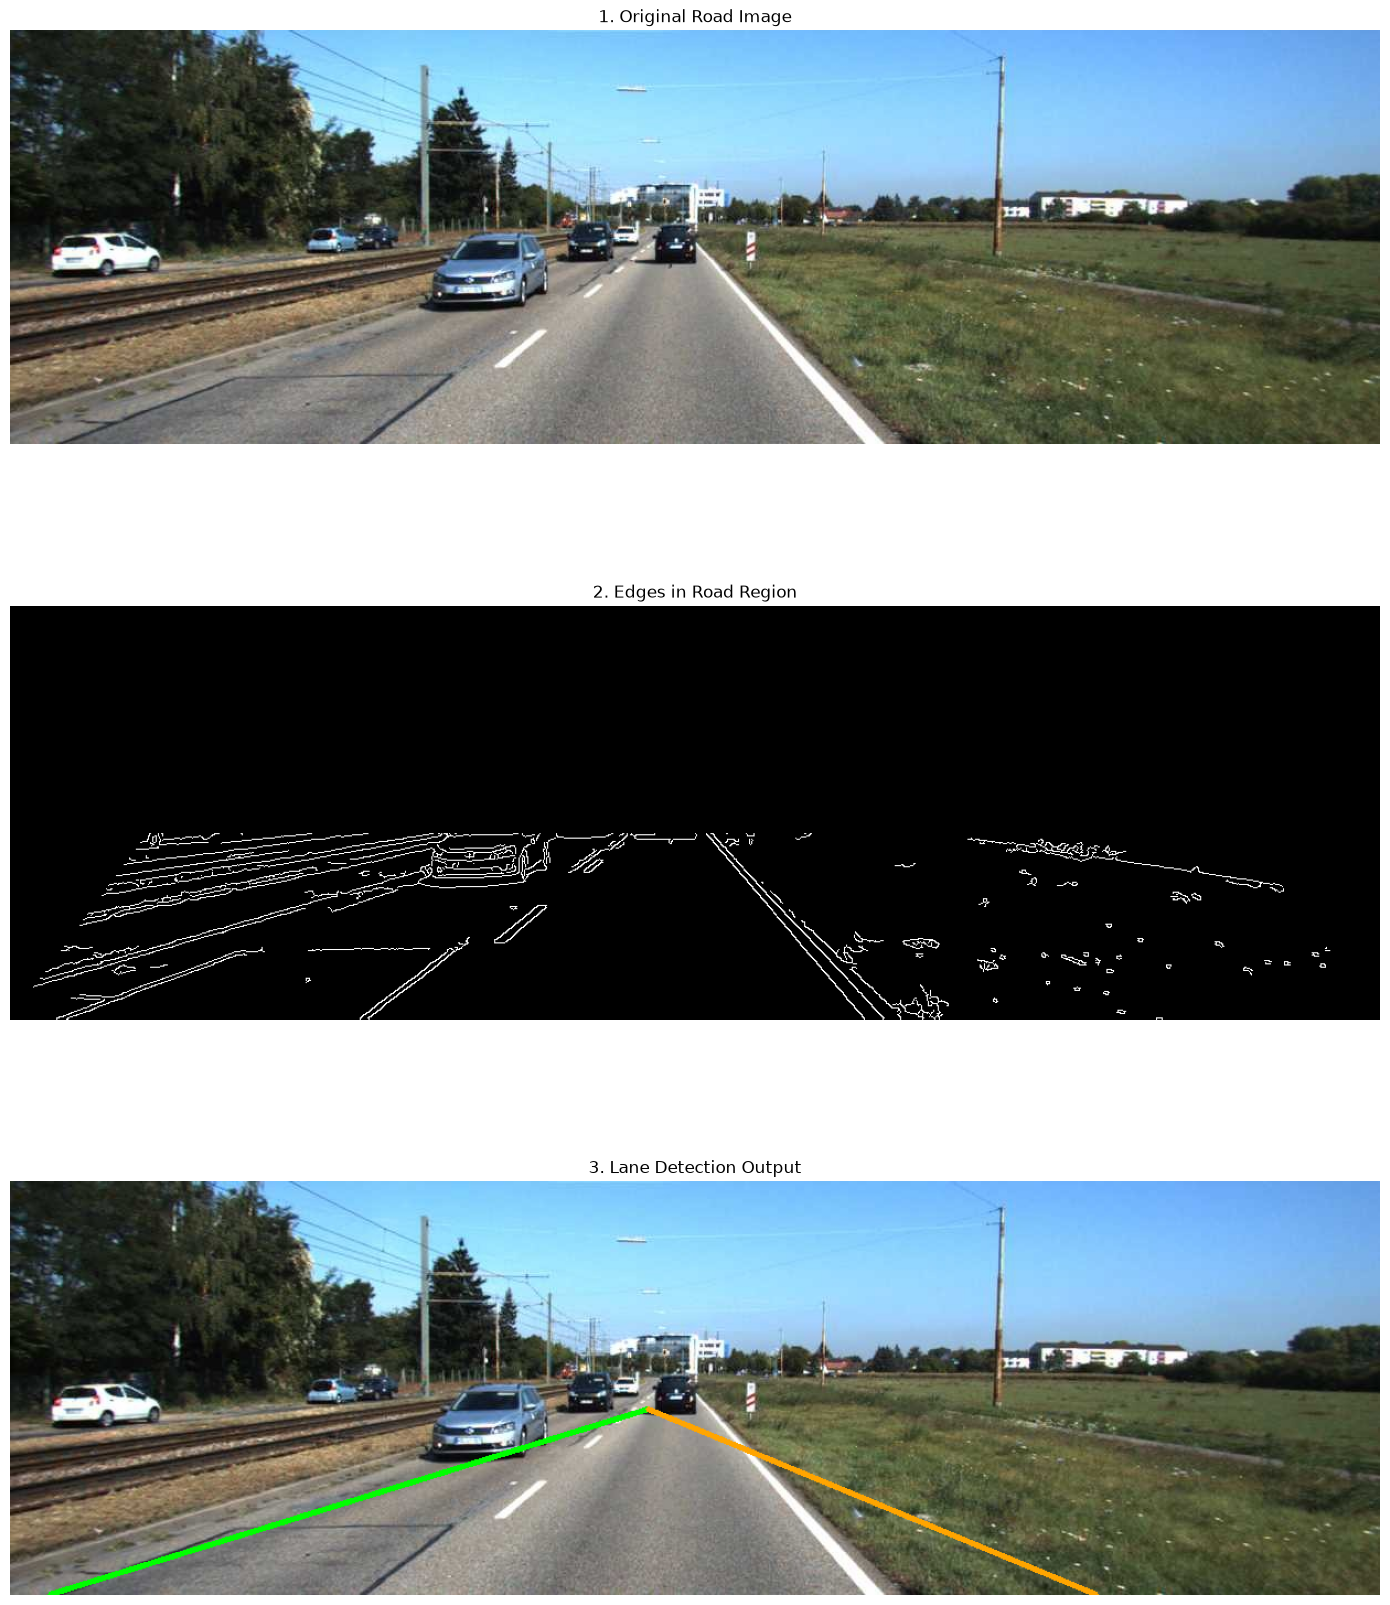

In [31]:
# Cell 3: Display images vertically

import cv2
import matplotlib.pyplot as plt
import numpy as np

# Recreate the edge image
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 0)
edges = cv2.Canny(blur, 50, 150)

# Apply road-region mask
height, width = edges.shape
mask = np.zeros_like(edges)

polygon = np.array([[
    (0, height),
    (int(width * 0.1), int(height * 0.55)),
    (int(width * 0.9), int(height * 0.55)),
    (width, height)
]], dtype=np.int32)

cv2.fillPoly(mask, polygon, 255)
edges_roi = cv2.bitwise_and(edges, mask)

# Display vertically
fig, axes = plt.subplots(3, 1, figsize=(14, 18))

axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title("1. Original Road Image")
axes[0].axis("off")

axes[1].imshow(edges_roi, cmap="gray")
axes[1].set_title("2. Edges in Road Region")
axes[1].axis("off")

axes[2].imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
axes[2].set_title("3. Lane Detection Output")
axes[2].axis("off")

plt.tight_layout()
plt.show()